# Eva Data

This notebook builds a `MultiDataset` containing exactly one `ZarrDataset`, loads one batch, visualizes one image with `mediapy`, and prints the rest of the batch.

In [1]:
from pathlib import Path

import cv2
import imageio_ffmpeg
import mediapy as mpy
import numpy as np
import torch

from egowam.rldb.embodiment.eva import Eva, _build_eva_bimanual_transform_list
from egowam.rldb.embodiment.human import Aria
from egowam.rldb.zarr.zarr_dataset_multi import MultiDataset, ZarrDataset
from egowam.rldb.zarr.zarr_dataset_multi import S3EpisodeResolver
from egowam.utils.egowamUtils import (
    INTRINSICS,
    cam_frame_to_cam_pixels,
    nds,
)
from egowam.utils.aws.aws_data_utils import load_env

# Ensure mediapy can find an ffmpeg executable in this environment
mpy.set_ffmpeg(imageio_ffmpeg.get_ffmpeg_exe())

/coc/flash7/bli678/Projects/EgoVerse/emimic2/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
# TEMP_DIR = "/coc/flash7/scratch/egowm/egoverseS3ZarrDataset/aria_cup_saucer" # replace with your own temp directory for caching S3 data
TEMP_DIR = "/coc/flash7/scratch/egowm/tmp"
load_env()

In [5]:
key_map = Eva.get_keymap()
transform_list = Eva.get_transform_list()

resolver = S3EpisodeResolver(
    TEMP_DIR, key_map=key_map, transform_list=transform_list
)
# 2025-12-26-18-07-46-296000: orginal egoverse episode hash
# 2026-03-04-18-33-24-042000: white cemaric cup + green square saucer
# 2026-03-04-20-31-36-781000: white cup + yellow saucer
filters = {
    "episode_hash": "2026-04-29-15-28-46-706000"
}
multi_ds = MultiDataset._from_resolver(
    resolver, filters=filters, sync_from_s3=True, mode="total"
)

loader = torch.utils.data.DataLoader(multi_ds, batch_size=1, shuffle=False)

Tables in schema 'app': ['staging_microagi', 'episodes_lab_backup_20260804_microagi_yam', 'episodes_mp4_path_backup_20260804_microagi', 'staging_trace', 'episodes']
cp s3://rldb/processed_v3/eva/2026-04-29-15-28-46-706000.zarr/annotations/zarr.json /coc/flash7/scratch/egowm/tmp/2026-04-29-15-28-46-706000/annotations/zarr.json
cp s3://rldb/processed_v3/eva/2026-04-29-15-28-46-706000.zarr/images.left_wrist/zarr.json /coc/flash7/scratch/egowm/tmp/2026-04-29-15-28-46-706000/images.left_wrist/zarr.json
cp s3://rldb/processed_v3/eva/2026-04-29-15-28-46-706000.zarr/images.right_wrist/zarr.json /coc/flash7/scratch/egowm/tmp/2026-04-29-15-28-46-706000/images.right_wrist/zarr.json
cp s3://rldb/processed_v3/eva/2026-04-29-15-28-46-706000.zarr/images.front_1/zarr.json /coc/flash7/scratch/egowm/tmp/2026-04-29-15-28-46-706000/images.front_1/zarr.json
cp s3://rldb/processed_v3/eva/2026-04-29-15-28-46-706000.zarr/left.cmd_ee_pose/c/0/0 /coc/flash7/scratch/egowm/tmp/2026-04-29-15-28-46-706000/left.cmd_

""

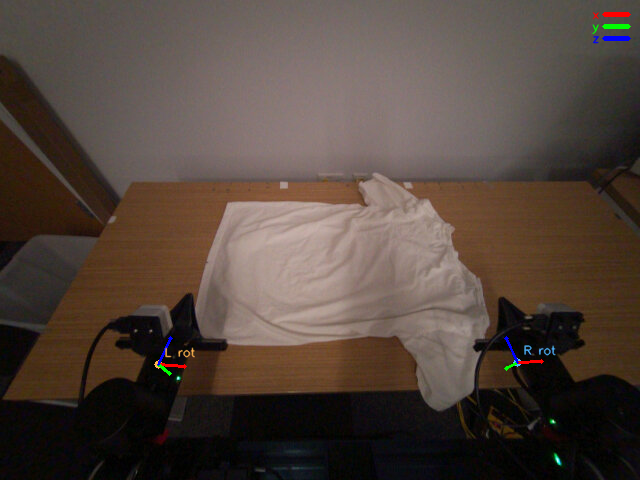

In [6]:
# Separate YPR visualization preview
for batch in loader:
    vis_ypr = Eva.viz_transformed_batch(batch, mode="palm_axes")
    mpy.show_image(vis_ypr)
    break

In [7]:
images = []
for i, batch in enumerate(loader):
    # mode: palm_traj, palm_axes
    vis = Eva.viz_transformed_batch(batch, mode="palm_axes")
    images.append(vis)
    # if i > 10:
    #     break

mpy.show_video(images, fps=30)

This browser does not support the video tag.


## Human Datasets
Mecka, Scale and Aria should all run exactly the same

In [1]:
from pathlib import Path

import cv2
import imageio_ffmpeg
import mediapy as mpy
import numpy as np
import torch

from egowam.rldb.embodiment.eva import Eva, _build_eva_bimanual_transform_list
from egowam.rldb.embodiment.human import Aria
from egowam.rldb.zarr.zarr_dataset_multi import MultiDataset, ZarrDataset
from egowam.rldb.zarr.zarr_dataset_multi import S3EpisodeResolver
from egowam.utils.egowamUtils import (
    INTRINSICS,
    cam_frame_to_cam_pixels,
    nds,
)
from egowam.utils.aws.aws_data_utils import load_env

# Ensure mediapy can find an ffmpeg executable in this environment
mpy.set_ffmpeg(imageio_ffmpeg.get_ffmpeg_exe())

${EGOWAM_VENV:-$ROOT/.venv}/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [5]:
intrinsics_key = "base"

TEMP_DIR = "/coc/flash7/scratch/egowm/tmp" # replace with your own temp directory for caching S3 data

key_map = Aria.get_keymap(use_future=True)
transform_list = Aria.get_transform_list(use_future=True)

resolver = S3EpisodeResolver(
    TEMP_DIR,
    key_map=key_map,
    transform_list=transform_list,
)

filters = {"episode_hash": "2026-01-03-10-20-21-689000"} #aria
# filters = {"episode_hash": "692ee048ef7557106e6c4b8d"} # mecka

cloudflare_ds = MultiDataset._from_resolver(
    resolver, filters=filters, sync_from_s3=True, mode="total"
)

loader = torch.utils.data.DataLoader(cloudflare_ds, batch_size=1, shuffle=False)

Tables in schema 'app': ['episodes']
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/left.obs_ee_pose/zarr.json /coc/flash7/scratch/egowm/tmp/2026-01-03-10-20-21-689000/left.obs_ee_pose/zarr.json
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/images.front_1/zarr.json /coc/flash7/scratch/egowm/tmp/2026-01-03-10-20-21-689000/images.front_1/zarr.json
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/annotations/zarr.json /coc/flash7/scratch/egowm/tmp/2026-01-03-10-20-21-689000/annotations/zarr.json
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/left.obs_keypoints/zarr.json /coc/flash7/scratch/egowm/tmp/2026-01-03-10-20-21-689000/left.obs_keypoints/zarr.json
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/left.obs_wrist_pose/zarr.json /coc/flash7/scratch/egowm/tmp/2026-01-03-10-20-21-689000/left.obs_wrist_pose/zarr.json
cp s3://rldb/processed_v3/aria/2026-01-03-10-20-21-689000.zarr/obs_eye_gaze/c/0/0 /coc/flash7/scr

In [6]:
len(cloudflare_ds)

3166

In [7]:
vis_interval = cloudflare_ds[1]['bound']
print("vis_interval", vis_interval)

ims = []
for i, batch in enumerate(loader):
    vis = Aria.viz_transformed_batch(batch, mode="palm_traj")
    ims.append(vis)
    # mpy.show_image(vis)

    # for k, v in batch.items():
    #     print(f"{k}: {tuple(v.shape)}")
    
    if i > vis_interval[-1]:
        break

mpy.show_video(ims, fps=30)


vis_interval tensor([  0., 546.])


This browser does not support the video tag.


In [ ]:
# Aria YPR video (same data loop, YPR overlay)
ims_ypr = []
for i, batch in enumerate(loader):
    vis_ypr = Aria.viz_transformed_batch(batch, mode="palm_axes")
    ims_ypr.append(vis_ypr)
    if i > 20:
        break

mpy.show_video(ims_ypr, fps=30)

## Aria Gaze

In [ ]:
from egowam.utils.egowamUtils import INTRINSICS, cam_frame_to_cam_pixels, draw_dot_on_frame, get_gaze_endpoint, ARIA_T_RGB_CPF
from egowam.rldb.zarr.zarr_dataset_multi import MultiDataset, ZarrDataset
import mediapy as mpy
import numpy as np
import torch
from pathlib import Path

key_map_gaze = {
    "images.front_1": {"zarr_key": "images.front_1"},
    "eye_gaze": {"zarr_key": "obs_eye_gaze"},
}
intrinsics = INTRINSICS["base"]


filters = {"episode_hash": "2025-11-27-23-14-02-277000"} #aria
# filters = {"episode_hash": "692ee048ef7557106e6c4b8d"} # mecka
resolver = S3EpisodeResolver(
    TEMP_DIR, key_map=key_map_gaze
)
cloudflare_ds = MultiDataset._from_resolver(
    resolver, filters=filters, sync_from_s3=True, mode="total"
)

loader = torch.utils.data.DataLoader(cloudflare_ds, batch_size=1, shuffle=False)

In [ ]:
ims_gaze = []
for i, batch in enumerate(loader):
    print(batch.keys())
    gaze_data = batch['eye_gaze'][0].numpy() # yaw (rads), pitch (rads), depth (m)
    if gaze_data[0] != -100: # value for no gaze estimate
        gaze_point_xyz = get_gaze_endpoint(gaze_data[0], gaze_data[1], gaze_data[2], ARIA_T_RGB_CPF)
        gaze_point_xyz = np.expand_dims(gaze_point_xyz, 0)
        gaze_point_pixel = cam_frame_to_cam_pixels(gaze_point_xyz, intrinsics)
        frame = batch['images.front_1'][0].permute(1,2,0).numpy() * 255
        vis = draw_dot_on_frame(frame, gaze_point_pixel, show=False)
        ims_gaze.append(vis)
        if i > 600:
            break

In [ ]:
mpy.show_video(ims_gaze, fps=30)

## Future Frames

Load the dataset with `use_future=True` to get current and future (at `idx + action_horizon`) images and proprio. The helper below visualizes them side by side per camera.

In [8]:
CAMERA_KEYS = [
    "observations.images.front_img_1",
    "observations.images.right_wrist_img",
    "observations.images.left_wrist_img",
]


def _to_hwc_uint8(x):
    """Tensor (C, H, W) or (1, C, H, W) -> (H, W, C) uint8."""
    if x.dim() == 4:
        x = x[0]
    return (x.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)


def viz_future_frames(batch, camera_keys=CAMERA_KEYS, action_horizon=45):
    """Return a side-by-side image: [current | future] per camera. Stack cameras vertically."""
    panels = []
    for cam_key in camera_keys:
        future_key = "future." + cam_key
        cur = _to_hwc_uint8(batch[cam_key])
        fut = _to_hwc_uint8(batch[future_key])
        cur_labeled = cv2.putText(
            cur.copy(), "current", (5, 20),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2
        )
        fut_labeled = cv2.putText(
            fut.copy(), f"future (+{action_horizon} steps)", (5, 20),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2
        )
        panels.append(np.concatenate([cur_labeled, fut_labeled], axis=1))
    return np.concatenate(panels, axis=0)


def viz_future_frames_sticky(batch_current, batch_future_ref, camera_keys=CAMERA_KEYS, action_horizon=45, future_display_idx=None):
    """Same layout as viz_future_frames but future frame is sticky: for idx in [0, action_horizon-1]
    use future at step action_horizon; at step action_horizon update to 2*action_horizon; etc.
    batch_future_ref is the batch at the chosen future index (use its current images as 'future')."""
    panels = []
    for cam_key in camera_keys:
        cur = _to_hwc_uint8(batch_current[cam_key])
        fut = _to_hwc_uint8(batch_future_ref[cam_key])
        cur_labeled = cv2.putText(
            cur.copy(), "current", (5, 20),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2
        )
        label = f"future (step {future_display_idx})" if future_display_idx is not None else "future"
        fut_labeled = cv2.putText(
            fut.copy(), label, (5, 20),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2
        )
        panels.append(np.concatenate([cur_labeled, fut_labeled], axis=1))
    return np.concatenate(panels, axis=0)

In [9]:
action_horizon = 45
key_map_future = Eva.get_keymap(action_horizon=action_horizon, use_future=True)
transform_list_future = _build_eva_bimanual_transform_list(use_future=True)

resolver_future = S3EpisodeResolver(
    TEMP_DIR, key_map=key_map_future, transform_list=transform_list_future
)
multi_ds_future = MultiDataset._from_resolver(
    resolver_future,
    filters={"episode_hash": "2025-12-26-18-07-46-296000"},
    sync_from_s3=False,
    mode="total",
)
loader_future = torch.utils.data.DataLoader(
    multi_ds_future, batch_size=1, shuffle=False
)

Tables in schema 'app': ['episodes']


In [12]:
# Sticky future: for idx in [0, 44] future = frame 45; at idx 45 future = frame 90; etc.
total_frames = len(multi_ds_future)
frames = []
for idx in range(total_frames):
    future_display_idx = min(((idx // action_horizon) + 1) * action_horizon, total_frames - 1)
    batch_current = multi_ds_future[idx]
    batch_future_ref = multi_ds_future[future_display_idx]
    vis = viz_future_frames_sticky(
        batch_current,
        batch_future_ref,
        action_horizon=action_horizon,
        future_display_idx=future_display_idx,
    )
    frames.append(vis)
    if idx > 200:
        break

mpy.show_video(frames, fps=30)

This browser does not support the video tag.
